<center><h1> <font color='blue'> 

**Proyecto Censo 2024**

Notebook 01: Preparación y validación de datos

</font></h1></center>


Este notebook carga y valida los microdatos del Censo 2024 (INE) y construye la base analítica que se usa en el notebook `02_analisis`. Es el respaldo metodológico del proyecto: cada decisión sobre los datos queda justificada aquí.

**Autor:** Nelson Hernández Becerra  
**Fecha:** octubre 2026  
**Herramientas:** Python, DuckDB, pandas

## Datos y alcance

- **Fuente:** Instituto Nacional de Estadísticas (INE), Censo 2024, microdatos de personas, hogares y viviendas.
- **Documentación:** Manual de Uso de Microdatos Censales, versión 12-12-2025.
- **Formato utilizado:** Parquet.
- **Fecha de descarga:** octubre 2026.

### Consideraciones metodológicas
- Los valores `-99` (no responde) y `-66` (suprimido por anonimización) se tratan por separado y no entran en los promedios.
- Las asociaciones que se reporten **no implican causalidad**.

<font color=blue>

## **1. Configuración y carga de datos** </font>

Se utiliza **DuckDB** para consultar los archivos Parquet directamente desde disco, sin cargarlos completos en memoria. La tabla de personas supera los 18 millones de registros, por lo que esta estrategia evita problemas de memoria y mantiene los tiempos de consulta bajos.

Se definen las rutas de los tres archivos (personas, hogares y viviendas), se comprueba que existan y se crea una **vista** de DuckDB por cada tabla. Una vista funciona como un acceso directo: permite escribir consultas como `FROM personas` sin repetir la ruta del archivo y sin copiar los datos.



In [1]:
import duckdb
from pathlib import Path

DATA_DIR = Path("../data/raw/viv_hog_per_censo2024")

RUTA_PERSONAS = DATA_DIR / "personas_censo2024.parquet"
RUTA_HOGARES = DATA_DIR / "hogares_censo2024.parquet"
RUTA_VIVIENDAS = DATA_DIR / "viviendas_censo2024.parquet"

# Comprobar que los archivos existen
for ruta in (RUTA_PERSONAS, RUTA_HOGARES, RUTA_VIVIENDAS):
    print(ruta.name, "->", "OK" if ruta.exists() else "NO ENCONTRADO")

# Conexión DuckDB
con = duckdb.connect()

for nombre, ruta in [
    ("personas", RUTA_PERSONAS),
    ("hogares", RUTA_HOGARES),
    ("viviendas", RUTA_VIVIENDAS),
]:
    con.sql(
        f"""
        CREATE OR REPLACE VIEW {nombre} AS
        SELECT *
        FROM read_parquet('{ruta.as_posix()}')
        """
    )

personas_censo2024.parquet -> OK
hogares_censo2024.parquet -> OK
viviendas_censo2024.parquet -> OK


>los tres archivos fueron encontrados y las vistas se crearon correctamente.

<font color=green>

### **1.1 Verificación del número de registros**

</font>

Como primera validación de integridad, se cuenta el total de filas de la tabla `personas` y se compara con el valor declarado en el Manual de Uso de Microdatos Censales del INE (versión 12-12-2025).

In [2]:
n_personas = con.sql("SELECT COUNT(*) FROM personas").fetchall()[0][0]
print(f"Registros en personas: {n_personas:,}")
print("Valor esperado según el manual: 18,480,432")

Registros en personas: 18,480,432
Valor esperado según el manual: 18,480,432




>la tabla contiene **18.480.432 registros**, cifra idéntica a la publicada por el INE. 

La descarga y lectura están completas, sin pérdidas ni duplicados evidentes.

*Nota técnica:* en la versión de DuckDB utilizada, el método `fetchone()` ya no está disponible sobre `con.sql()`, por lo que el conteo se obtiene con `fetchall()[0][0]`.

<font color=green>

### **1.2 Estructura de la tabla de personas**

</font>

Se inspecciona el esquema de la tabla (nombres y tipos de las columnas) con `DESCRIBE`, y luego se filtra a las variables clave del análisis.


In [3]:
con.sql("DESCRIBE personas").df()

,column_name,column_type,null,key,default,extra
0,id_vivienda,INTEGER,YES,None,None,None
1,id_hogar,INTEGER,YES,None,None,None
2,id_persona,INTEGER,YES,None,None,None
3,region,INTEGER,YES,None,None,None
4,provincia,INTEGER,YES,None,None,None
...,...,...,...,...,...,...
58,p47b_hijas_sobrev,INTEGER,YES,None,None,None
59,p47c_hijos_sobrev,INTEGER,YES,None,None,None
60,p48_anio_nac_uh,INTEGER,YES,None,None,None
61,p48_mes_nac_uh,INTEGER,YES,None,None,None


In [4]:
cols_clave = ["id_vivienda", "id_hogar", "id_persona", "escolaridad",
              "cine11", "edad", "sexo", "tipo_operativo"]

desc = con.execute("DESCRIBE personas").df()
desc[desc["column_name"].isin(cols_clave)][["column_name", "column_type"]]

,column_name,column_type
0,id_vivienda,INTEGER
1,id_hogar,INTEGER
2,id_persona,INTEGER
8,tipo_operativo,INTEGER
9,sexo,INTEGER
10,edad,INTEGER
44,escolaridad,INTEGER
45,cine11,INTEGER


**Se muestra que**
 - La tabla tiene **63 columnas**.
 - Las ocho variables clave están presentes: `id_vivienda`, `id_hogar`, `id_persona`, `tipo_operativo`, `sexo`, `edad`, `escolaridad` y `cine11`.
 - Todas están almacenadas como `INTEGER`. Las variables categóricas (`sexo`, `cine11`, `tipo_operativo`) están codificadas numéricamente, por lo que sus códigos se interpretan con el diccionario del manual y **no** se promedian. `escolaridad` (años de estudio) y `edad` sí son variables numéricas.
 - La columna `null = YES` que muestra `DESCRIBE` es solo la declaración por defecto de Parquet, no indica la presencia de valores vacíos. Los valores faltantes se cuantifican por separado.

**Nota**
- Se descarta `div_genero`: es una variable sensible, aplica solo a mayores de 18 años y tiene alta proporción de valores suprimidos por anonimización (`-66`), por lo que no aporta a la pregunta de investigación.

<font color = green>

### **1.3 Valores especiales**

</font>


Según el manual del INE, estos códigos se repiten en todas las tablas:

| Valor | Significado |
|---|---|
| `-99` | La persona no respondió la pregunta |
| `-66` | Valor suprimido por anonimización |
| `NULL` | La pregunta no aplica a esa unidad |

Ninguno de ellos debe entrar en cálculos de promedios. En las secciones siguientes se cuantifica su presencia en cada variable antes de excluirlos.|

<font color=green>

### **1.4 Tipo de operativo y escolaridad**

</font>

La base mezcla tres tipos de operativo censal: `viviendas particulares`, `viviendas colectivas` y `personas en situación de calle`. Estos grupos no tienen las mismas variables de hogar y vivienda, por lo que se cuantifica cuántas personas hay en cada uno y se contrasta con las cifras del manual del INE (18.339.655 en vivienda particular y 119.027 en colectiva).

In [5]:
con.execute("""
    SELECT
        tipo_operativo,
        COUNT(*) AS n,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 3) AS pct
    FROM personas
    GROUP BY tipo_operativo
    ORDER BY tipo_operativo
""").df()

,tipo_operativo,n,pct
0,1,21750,0.118
1,2,18339655,99.238
2,3,119027,0.644


> El 99,24 % de los registros (18.339.655) corresponde a vivienda particular, el 0,64 % (119.027) a vivienda colectiva y el 0,12 % (21.750) a personas en situación de calle. Las cifras coinciden con las del manual del INE.

Para los análisis que requieran variables de hogar y vivienda se trabajará solo con vivienda particular, ya que colectivas y calle no tienen esas variables y representan menos del 1 % de la población.

In [6]:
con.execute("""
    SELECT
        escolaridad,
        COUNT(*) AS n,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 3) AS pct
    FROM personas
    GROUP BY escolaridad
    ORDER BY escolaridad
""").df()

,escolaridad,n,pct
0,-99,132058,0.715
1,0,1474640,7.979
2,1,328448,1.777
3,2,360885,1.953
4,3,461424,2.497
5,4,514230,2.783
6,5,456048,2.468
7,6,668991,3.620
8,7,523391,2.832
9,8,1211652,6.556


> `escolaridad` toma valores entre 0 y 24 años, más el código `-99` (no responde), presente en 132.058 personas (0,72 %). No se observan valores `-66` ni `NULL`.

 **A destacar**
- El valor 0 agrupa al 7,98 % de la población, que incluye a niños en edad preescolar. Para analizar el nivel educativo real se trabajará con adultos de 25 años o más.
- La distribución presenta picos en 8, 12, 15 y 17 años, que serían consistentes con la finalización de ciclos educativos. El mayor es 12 años (23,9 %), coherente con enseñanza media completa.
- Los registros `-99` se excluirán de los promedios.

<font color=green>

### **1.5 Distribución de los años de escolaridad**

</font>

Se grafica la distribución de `escolaridad` excluyendo el código `-99` (no responde), para visualizar cómo se concentra la población según años de estudio completados.

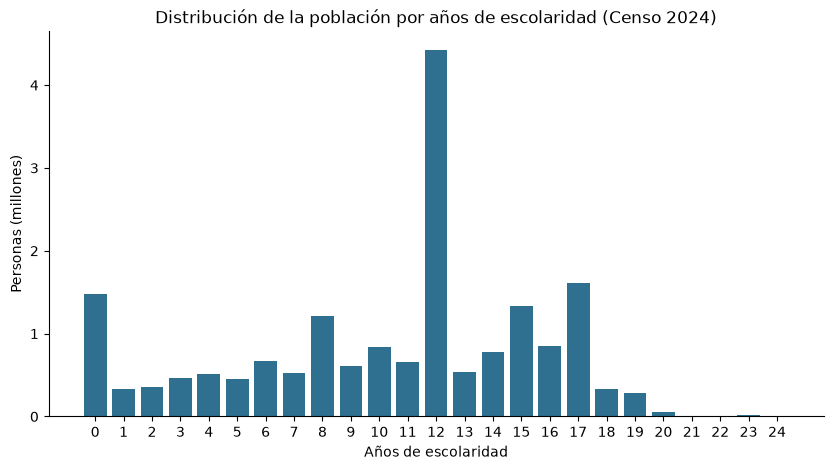

In [7]:
import matplotlib.pyplot as plt

df_esc = con.execute("""
    SELECT escolaridad, COUNT(*) AS n
    FROM personas
    WHERE escolaridad >= 0
    GROUP BY escolaridad
    ORDER BY escolaridad
""").df()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(df_esc["escolaridad"], df_esc["n"] / 1e6, color="#2f6f8f")
ax.set_title("Distribución de la población por años de escolaridad (Censo 2024)")
ax.set_xlabel("Años de escolaridad")
ax.set_ylabel("Personas (millones)")
ax.set_xticks(range(0, 25))
ax.spines[["top", "right"]].set_visible(False)
plt.show()

> La distribución es multimodal, con un máximo claro en 12 años (enseñanza media completa) y picos secundarios en 8, 15 y 17 años (8vo basico, carrera tecnica y carrera profesional)

Respecto al valor 0, el manual lo explica: se asigna 0 años a “nunca asistió”, sala cuna, jardín infantil, prekínder, kinder y educación especial o diferencial. Es decir, ese 7,98 % mezcla personas sin educación formal con niños en educación preescolar, y esa mezcla es la razón por la que no sirve para comparar adultos. La cola sobre los 20 años tambien es un punto destacado.

<font color=green>

### **1.6 Escolaridad promedio: replicación del indicador educ01**

</font>

El manual del INE define el indicador **educ01** como el promedio de años de escolaridad de toda la población, excluyendo los registros sin respuesta (`-99`). Se replica ese cálculo y se compara con el promedio de las personas de **25 años o más**, edad a la que la mayoría ya completó su formación.

La diferencia importa: el universo oficial incluye niños y jóvenes que aún están estudiando, lo que baja el promedio y no refleja el nivel educativo alcanzado por la población adulta.

In [8]:
con.execute("""
    SELECT 'Toda la población (educ01)' AS grupo,
           COUNT(*) AS n,
           ROUND(AVG(escolaridad), 2) AS prom_escolaridad
    FROM personas
    WHERE escolaridad != -99

    UNION ALL

    SELECT 'Adultos de 25 años o más' AS grupo,
           COUNT(*) AS n,
           ROUND(AVG(escolaridad), 2) AS prom_escolaridad
    FROM personas
    WHERE escolaridad != -99 AND edad >= 25
""").df()

,grupo,n,prom_escolaridad
0,Toda la población (educ01),18348374,10.38
1,Adultos de 25 años o más,12517005,12.04


> El promedio de escolaridad de toda la población (indicador educ01) es de **10,4 años**, mientras que el de las personas de 25 años o más es de **12,0 años**.

La diferencia se explica por la composición del universo: educ01 incluye a niños y jóvenes que aún cursan su educación, con pocos años acumulados. Para describir el nivel educativo alcanzado por la población, y para comparar grupos, se trabajará con adultos de 25 años o más, edad a la que la mayoría ha completado su formación.

<font color =green>

### **1.7 Validación contra la Síntesis de Resultados del INE**

</font>

La Síntesis de Resultados del Censo 2024 reporta una escolaridad promedio de **12,1 años** para las personas de 18 años o más, con igual valor para hombres y mujeres. Se replica ese cálculo para contrastar la base con la cifra oficial.

In [9]:
con.execute("""
    SELECT
        CASE sexo WHEN 1 THEN 'Hombre' WHEN 2 THEN 'Mujer' END AS sexo,
        COUNT(*) AS n,
        ROUND(AVG(escolaridad), 2) AS prom_escolaridad
    FROM personas
    WHERE escolaridad != -99 AND edad >= 18
    GROUP BY sexo

    UNION ALL

    SELECT 'Total', COUNT(*), ROUND(AVG(escolaridad), 2)
    FROM personas
    WHERE escolaridad != -99 AND edad >= 18
""").df()

,sexo,n,prom_escolaridad
0,Hombre,6808196,12.16
1,Mujer,7437308,12.13
2,Total,14245504,12.14


In [10]:
con.execute("""
    SELECT
        CASE sexo WHEN 1 THEN 'Hombre' WHEN 2 THEN 'Mujer' END AS sexo,
        COUNT(*) AS n,
        ROUND(AVG(escolaridad), 3) AS prom_escolaridad
    FROM personas
    WHERE escolaridad != -99 AND edad >= 18 AND tipo_operativo = 2
    GROUP BY sexo

    UNION ALL

    SELECT 'Total', COUNT(*), ROUND(AVG(escolaridad), 3)
    FROM personas
    WHERE escolaridad != -99 AND edad >= 18 AND tipo_operativo = 2
""").df()

,sexo,n,prom_escolaridad
0,Hombre,6721085,12.186
1,Mujer,7412541,12.136
2,Total,14133626,12.159


La Síntesis de Resultados del Censo 2024 reporta una escolaridad promedio de **12,1 años** para las personas de 18 años o más, con igual valor para hombres y mujeres. Se replica el cálculo (excluyendo `-99`) para contrastar la base con la cifra oficial, y luego se repite restringiendo a vivienda particular para evaluar si el universo explica alguna diferencia.

| Universo (18 años o más) | Hombres | Mujeres | Total |
|---|---|---|---|
| Todos los operativos | 12,16 | 12,13 | 12,14 |
| Solo vivienda particular | 12,19 | 12,14 | 12,16 |
| INE (Síntesis) | 12,1 | 12,1 | 12,1 |

> El promedio total (12,14) y el de mujeres (12,13) coinciden con la cifra del INE al redondear a un decimal, y se reproduce la conclusión de que **no existe brecha de género** en años de escolaridad.
>
> El promedio de hombres (12,16) redondea a 12,2, mientras el INE reporta 12,1. 

Restringir el análisis a vivienda particular no reduce esa diferencia, sino que la aumenta levemente (12,19). Por lo tanto, el universo no explica la discrepancia. Una posible causa es una diferencia de versión de los datos o de definición de población entre la Síntesis y los microdatos, pero no pudo verificarse. La diferencia es de aproximadamente 0,06 años y no altera las conclusiones.

Se continúa con los microdatos tal como están, documentando esta diferencia menor.

<font color=green>

### **1.8 Verificación de las tablas de hogares y viviendas**

</font>

Antes de unir las tres tablas, se comprueba que hogares y viviendas también estén completas, contrastando su número de registros con el declarado en el Manual de Uso de Microdatos Censales del INE.

Además, se comprueba que las llaves identificadoras no se repitan, comparando el número de filas con el de combinaciones distintas de identificadores. Esto es necesario antes de unir las tablas, porque una llave duplicada multiplicaría filas en la unión.


#### **1.8.1 Verificación de las columnas seleccionadas**

Se comprueba que las variables elegidas para el análisis existan en las tablas correspondientes.

In [11]:
# Se comprueba que existen las columnas elegidas
columnas = {
    "personas": ["sit_fuerza_trabajo", "p40_cise_rec", "cod_ciuo", "p27_nacionalidad"],
    "hogares": ["p12_tenencia_viv", "p15b_serv_compu", "p15d_serv_internet_fija",
                "p15e_serv_internet_movil", "p15f_serv_internet_satelital"],
    "viviendas": ["indice_hacinamiento"],
}

for tabla, lista in columnas.items():
    presentes = set(con.execute(f"DESCRIBE {tabla}").df()["column_name"])
    faltan = [c for c in lista if c not in presentes]
    print(tabla, "->", faltan if faltan else "todas presentes")

personas -> todas presentes
hogares -> todas presentes
viviendas -> todas presentes


> Todas las variables están presentes: `sit_fuerza_trabajo`, `p40_cise_rec`, `cod_ciuo` y `p27_nacionalidad` en `personas`; `p12_tenencia_viv`, `p15b_serv_compu`, `p15d_serv_internet_fija`, `p15e_serv_internet_movil` y `p15f_serv_internet_satelital` en `hogares`; e `indice_hacinamiento` en `viviendas`.

#### **1.8.2 Número de registros y unicidad de las llaves en hogares y personas**

Se contrastan los registros de las tablas de viviendas y hogares con los del manual, y se comprueba que las llaves de personas y hogares no se repitan.

In [12]:
# Conteo de filas (el manual indica 7.664.466 viviendas y 6.622.597 hogares)
for t in ["viviendas", "hogares"]:
    n = con.execute(f"SELECT COUNT(*) FROM {t}").fetchall()[0][0]
    print(f"{t}: {n:,}")

# Unicidad de las llaves: si las dos cifras son iguales, la llave no se repite
con.execute("""
    SELECT
        (SELECT COUNT(*) FROM personas) AS filas_personas,
        (SELECT COUNT(*) FROM (SELECT DISTINCT id_vivienda, id_hogar, id_persona FROM personas)) AS llaves_personas,
        (SELECT COUNT(*) FROM hogares) AS filas_hogares,
        (SELECT COUNT(*) FROM (SELECT DISTINCT id_vivienda, id_hogar FROM hogares)) AS llaves_hogares
""").df()

viviendas: 7,664,466
hogares: 6,622,597


,filas_personas,llaves_personas,filas_hogares,llaves_hogares
0,18480432,18480432,6622597,6622597


> La tabla de viviendas contiene **7.664.466** registros y la de hogares **6.622.597**, cifras idénticas a las declaradas por el INE en el manual.

En `personas` (`id_vivienda` + `id_hogar` + `id_persona`) y en `hogares` (`id_vivienda` + `id_hogar`), el número de llaves distintas es igual al número de filas (18.480.432 y 6.622.597, respectivamente). 
>No existen registros duplicados.


#### **1.8.3 Unicidad de la llave de viviendas**

Se verifica que `id_vivienda` identifique de forma única a cada registro de la tabla de viviendas, comparando el número total de filas con el de identificadores distintos.

In [13]:
con.execute("""
    SELECT
        COUNT(*) AS filas_viviendas,
        COUNT(DISTINCT id_vivienda) AS llaves_viviendas
    FROM viviendas
""").df()

,filas_viviendas,llaves_viviendas
0,7664466,7664466


> La tabla de viviendas tiene **7.664.466** filas y **7.664.466** valores distintos de `id_vivienda`, por lo que la llave es única.

Las tres tablas (personas, hogares y viviendas) contienen el número de registros declarado por el INE y sus llaves identificadoras no presentan duplicados. Las uniones entre tablas pueden realizarse sin riesgo de multiplicar filas.

<font color=green>

### **1.9 Revisión de las variables de vida diaria**

</font>

Antes de construir la base analítica, se revisa la distribución de cada variable elegida: sus categorías, la presencia de valores especiales (`-99`, `NA`) y la frecuencia de cada categoría. Se define una función auxiliar para repetir el procedimiento con todas las variables.

#### **1.9.1 Situación en la fuerza de trabajo (`sit_fuerza_trabajo`)**

Variable de `personas` que clasifica a las personas de 15 años o más en ocupadas (1), desocupadas (2) o fuera de la fuerza de trabajo (3). Según el manual, a las personas menores de 15 años no se les aplica la pregunta, por lo que aparecen como `NA`.

In [14]:
def frecuencias(tabla, variable):
    return con.execute(f"""
        SELECT {variable} AS valor,
               COUNT(*) AS n,
               ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
        FROM {tabla}
        GROUP BY {variable}
        ORDER BY {variable}
    """).df()

frecuencias("personas", "sit_fuerza_trabajo")

,valor,n,pct
0,-99,89526,0.48
1,1,8277501,44.79
2,2,777920,4.21
3,3,6060837,32.80
4,<NA>,3274648,17.72


> Las frecuencias coinciden con las del manual del INE. Del total de 18.480.432 personas, 8.277.501 (44,79 %) están ocupadas, 777.920 (4,21 %) desocupadas y 6.060.837 (32,80 %) fuera de la fuerza de trabajo. Hay 89.526 registros `-99` (0,48 %) y 3.274.648 `NA` (17,72 %), que corresponden a menores de 15 años, a quienes no se aplica la pregunta.

Al restringir el análisis a personas de 25 años o más, los `NA` no deberían estar presentes y los `-99` se tratarán como datos faltantes. Se debe considerar que la categoría "fuera de la fuerza de trabajo" incluye personas jubiladas, por lo que la edad deberá controlarse en el análisis.

#### **1.9.2 Categoría ocupacional (`p40_cise_rec`)**

Variable de `personas` que clasifica a las personas ocupadas según su categoría en el empleo: independiente (1), dependiente (2) o trabajador familiar no remunerado (3). Solo aplica a personas ocupadas, por lo que se espera que el resto aparezca como `NA`.

In [15]:
frecuencias("personas", "p40_cise_rec")

,valor,n,pct
0,-99,3458,0.02
1,1,2794082,15.12
2,2,5352532,28.96
3,3,127429,0.69
4,<NA>,10202931,55.21


> Las frecuencias coinciden con las del manual del INE. Entre las personas ocupadas (8.277.501), 5.352.532 son dependientes, 2.794.082 independientes y 127.429 trabajadores familiares no remunerados; 3.458 registros son `-99`. Estas cuatro cifras suman exactamente el número de personas ocupadas de `sit_fuerza_trabajo`, lo que confirma la coherencia entre ambas variables.

Los 10.202.931 registros `NA` (55,21 %) no son datos faltantes, sino personas que no están ocupadas (desocupadas, fuera de la fuerza de trabajo y menores de 15 años). La categoría 3 es muy pequeña (1,5 % de las personas ocupadas).

Esta variable solo se usará en análisis restringidos a personas ocupadas. Los `NA` no se eliminarán como si fueran datos perdidos, sino que se excluirán del análisis de calidad del empleo por definición del universo.

#### **1.9.3 Ocupación (`cod_ciuo`)**

Variable de `personas` que clasifica la ocupación de las personas ocupadas según la CIUO-08.CL a un dígito: de 1 (directores, gerentes y administradores) a 9 (ocupaciones elementales), más 0 (fuerzas armadas). Además de `-99` (no responde) y `NA` (no aplica), incluye el código `999`, que corresponde a una respuesta que no pudo codificarse.

In [16]:
frecuencias("personas", "cod_ciuo")

,valor,n,pct
0,-99,20547,0.11
1,0,24165,0.13
2,1,383706,2.08
3,2,1490307,8.06
4,3,884233,4.78
5,4,518314,2.80
6,5,1622622,8.78
7,6,224291,1.21
8,7,1038385,5.62
9,8,662440,3.58


> Las frecuencias coinciden con las del manual del INE. Entre las personas ocupadas (8.277.501), los grupos más numerosos son trabajadores de servicios y vendedores (1.622.622; 19,6 %), profesionales, científicos e intelectuales (1.490.307; 18,0 %) y ocupaciones elementales (1.132.704; 13,7 %). Las filas con valor suman exactamente el total de personas ocupadas, y los `NA` (10.202.931) coinciden con los de `p40_cise_rec`.

275.787 registros (`999`) tienen una ocupación declarada pero no codificable, y 20.547 (`-99`) no respondieron; en conjunto representan cerca del 3,6 % de las personas ocupadas y se tratarán como sin dato. Las fuerzas armadas (código 0) son un grupo muy pequeño.

Al construir la base analítica se evaluará si agrupar los diez grupos ocupacionales en menos categorías, justificando el criterio.

#### **1.9.4 Índice de hacinamiento (`indice_hacinamiento`)**

Variable de `viviendas` que clasifica cada vivienda particular ocupada según su nivel de hacinamiento: sin hacinamiento (1), hacinamiento medio (2) o hacinamiento crítico (3). La unidad de esta tabla es la vivienda, por lo que las frecuencias se refieren a viviendas y no a personas. Los registros `NA` corresponden a viviendas fuera del universo (por ejemplo, desocupadas, colectivas o situación de calle).

In [17]:
frecuencias("viviendas", "indice_hacinamiento")

,valor,n,pct
0,-99,1034,0.01
1,1,6039952,78.80
2,2,330955,4.32
3,3,36231,0.47
4,<NA>,1256294,16.39


> Las frecuencias coinciden con las del manual del INE y suman las 7.664.466 viviendas. Entre las viviendas con respuesta válida (6.407.138), el 94,3 % no presenta hacinamiento, el 5,2 % presenta hacinamiento medio y el 0,6 % hacinamiento crítico. Hay 1.034 registros `-99` y 1.256.294 `NA`.

La unidad de esta tabla es la vivienda, por lo que estos porcentajes no equivalen a porcentajes de personas: al asignar el índice a cada persona, las viviendas hacinadas pesarán más, porque albergan más personas. La categoría de hacinamiento crítico es muy pequeña y podría requerir agruparse con el hacinamiento medio.

Se definirá en la sección 2 si se mantienen las tres categorías o se agrupan.

#### **1.9.5 Tenencia de la vivienda (`p12_tenencia_viv`)**

Variable de `hogares` que indica bajo qué condición el hogar ocupa su vivienda: 

- propia pagada (1), 
- propia pagándose (2), 
- arrendada con contrato (3), 
- arrendada sin contrato (4), 
- cedida por trabajo o servicio (5), 
- cedida por familiar u otro (6), 
- usufructo (7), 
- ocupada de hecho (8) o 
- propiedad en sucesión o litigio (9). 

La unidad de esta tabla es el hogar.

In [18]:
frecuencias("hogares", "p12_tenencia_viv")

,valor,n,pct
0,-99,1096,0.02
1,1,3120238,47.12
2,2,910247,13.74
3,3,1229328,18.56
4,4,498871,7.53
5,5,90697,1.37
6,6,511118,7.72
7,7,61019,0.92
8,8,57788,0.87
9,9,116125,1.75


> Las frecuencias coinciden con las del manual del INE y suman los 6.622.597 hogares. El 60,9 % de los hogares ocupa una vivienda propia (47,1 % pagada y 13,7 % pagándose), el 26,1 % arrienda (18,6 % con contrato y 7,5 % sin contrato), el 9,1 % la ocupa en calidad de cedida y cerca del 3,5 % está en otras situaciones (usufructo, ocupación de hecho o propiedad en sucesión o litigio). Hay 1.096 registros `-99`.

Los 26.070 registros `NA` corresponden a personas en situación de calle (21.750) y viviendas colectivas (4.320), que no constituyen hogares con una vivienda propia o arrendada. La unidad de esta tabla es el hogar.

Que por definir en la sección 2 una agrupación de las nueve categorías (por ejemplo, propia, arrendada, cedida y otra), y evaluar si se mantiene la distinción entre arriendo con y sin contrato.

#### **1.9.6 Computador en el hogar (`p15b_serv_compu`)**

Variable de `hogares` que indica si el hogar dispone de computador (de escritorio o portátil): sí (1) o no (2). Es un indicador de acceso a tecnología. La unidad de esta tabla es el hogar.

In [19]:
frecuencias("hogares", "p15b_serv_compu")

,valor,n,pct
0,-99,10785,0.16
1,1,3621619,54.69
2,2,2964123,44.76
3,<NA>,26070,0.39


> Las frecuencias coinciden con las del manual del INE y suman los 6.622.597 hogares. El 54,7 % de los hogares dispone de computador y el 44,8 % no; hay 10.785 registros `-99` (0,16 %) y 26.070 `NA` (0,39 %), correspondientes a personas en situación de calle y viviendas colectivas.

Entre los hogares con respuesta válida (6.585.742), la distribución es cercana a la mitad (55,0 % sí, 45,0 % no). Esta variabilidad la hace útil para contrastar grupos.

#### **1.9.7 Internet fija (`p15d_serv_internet_fija`)**

Variable de `hogares` que indica si el hogar dispone de internet fija: sí (1) o no (2). Se revisa junto con las variables de internet móvil y satelital para evaluar cuál aporta mayor variabilidad como indicador de acceso digital.

In [20]:
frecuencias("hogares", "p15d_serv_internet_fija")

,valor,n,pct
0,-99,7571,0.11
1,1,4250122,64.18
2,2,2338834,35.32
3,<NA>,26070,0.39


> Las frecuencias coinciden con las del manual del INE y suman los 6.622.597 hogares. El 64,2 % de los hogares dispone de internet fija y el 35,3 % no; hay 7.571 registros `-99` (0,11 %) y 26.070 `NA` (0,39 %).

Entre los hogares con respuesta válida (6.588.956), el 64,5 % tiene internet fija, lo que le da a la variable buena capacidad para distinguir entre hogares. Además, la proporción de hogares con internet fija (64,2 %) es mayor que la de hogares con computador (54,7 %), por lo que ambos indicadores miden aspectos distintos del acceso digital y se mantendrán por separado.

#### **1.9.8 Internet móvil (`p15e_serv_internet_movil`)**

Variable de `hogares` que indica si el hogar dispone de internet móvil desde un celular, tablet o BAM: sí (1) o no (2). Se revisa para evaluar si aporta variabilidad suficiente como indicador de acceso digital.

In [21]:
frecuencias("hogares", "p15e_serv_internet_movil")

,valor,n,pct
0,-99,7572,0.11
1,1,5734118,86.58
2,2,854837,12.91
3,<NA>,26070,0.39


> Las frecuencias coinciden con las del manual del INE y suman los 6.622.597 hogares. El 86,6 % de los hogares dispone de internet móvil y el 12,9 % no; hay 7.572 registros `-99` (0,11 %) y 26.070 `NA` (0,39 %).

Entre los hogares con respuesta válida (6.588.955), el 87,0 % tiene internet móvil, por lo que la variable presenta menor variabilidad que internet fija y computador. Aun así, los 854.837 hogares sin conexión móvil constituyen un grupo relevante en términos absolutos.

Luego se tendra que evaluar en la sección 2 un indicador combinado de acceso a internet (por ejemplo, hogares sin internet fija ni móvil).

#### **1.9.9 Internet satelital (`p15f_serv_internet_satelital`)**

Variable de `hogares` que indica si el hogar dispone de internet por conexión satelital: sí (1) o no (2). Se revisa para evaluar si aporta variabilidad suficiente como indicador de acceso digital.

In [22]:
frecuencias("hogares", "p15f_serv_internet_satelital")

,valor,n,pct
0,-99,14919,0.23
1,1,288473,4.36
2,2,6293135,95.03
3,<NA>,26070,0.39


> Las frecuencias coinciden con las del manual del INE y suman los 6.622.597 hogares. Solo el 4,4 % de los hogares dispone de internet satelital (288.473), el 95,0 % no (6.293.135); hay 14.919 registros `-99` (0,23 %) y 26.070 `NA` (0,39 %).

La variable presenta muy baja variabilidad, ya que la gran mayoría de los hogares responde "no". Esto limita su capacidad para distinguir entre grupos.

Entonces `p15f_serv_internet_satelital` no se utilizará como variable independiente. Se evaluará su incorporación únicamente dentro de un indicador combinado de acceso a internet en la sección 2.

#### **1.9.10 Nacionalidad (`p27_nacionalidad`)**

Variable de `personas` que clasifica a todas las personas según su nacionalidad: chilena exclusivamente (1), chilena y otra, es decir, doble nacionalidad (2), u otra nacionalidad (3). Además de `-99` (no responde), incluye `-66` (valor suprimido por anonimización). Se utilizará principalmente como variable de control.

In [23]:
frecuencias("personas", "p27_nacionalidad")

,valor,n,pct
0,-99,100883,0.55
1,-66,151199,0.82
2,1,16500963,89.29
3,2,242909,1.31
4,3,1484478,8.03


> Las frecuencias coinciden con las del manual del INE y suman las 18.480.432 personas. El 89,3 % es de nacionalidad chilena exclusivamente (16.500.963), el 8,0 % tiene otra nacionalidad (1.484.478) y el 1,3 % doble nacionalidad (242.909). Hay 151.199 registros `-66` (0,82 %) y 100.883 `-99` (0,55 %); no hay `NA`.

La categoría "otra nacionalidad" tiene un peso suficiente (8 %) para usarse como variable de control. La doble nacionalidad es una categoría pequeña (1,3 %) que podría agruparse con alguna de las otras; esa decisión se toma en la sección 2. Los valores `-66` y `-99` suman cerca del 1,4 % y se tratarán como sin dato.

#### **1.9.11 Resumen de las variables y decisiones pendientes**

| Variable | Tabla (unidad) | Aplica a | Observaciones | Uso previsto |
|---|---|---|---|---|
| `sit_fuerza_trabajo` | personas (persona) | 15 años o más | `-99`: 0,48 %; `NA` corresponde a menores de 15 años | Participación laboral |
| `p40_cise_rec` | personas (persona) | Personas ocupadas | Categoría 3 muy pequeña (1,5 % de los ocupados) | Calidad del empleo |
| `cod_ciuo` | personas (persona) | Personas ocupadas | 10 grupos; `999` y `-99` suman cerca del 3,6 % de los ocupados | Tipo de ocupación; evaluar agrupar |
| `indice_hacinamiento` | viviendas (vivienda) | Viviendas particulares ocupadas | Hacinamiento crítico: 0,47 % | Vivienda; evaluar agrupar categorías |
| `p12_tenencia_viv` | hogares (hogar) | Hogares en vivienda particular | 9 categorías | Vivienda; agrupar (propia, arrendada, cedida, otra) |
| `p15b_serv_compu` | hogares (hogar) | Hogares en vivienda particular | 55 % sí, 45 % no | Acceso digital |
| `p15d_serv_internet_fija` | hogares (hogar) | Hogares en vivienda particular | 64 % sí, 35 % no | Acceso digital |
| `p15e_serv_internet_movil` | hogares (hogar) | Hogares en vivienda particular | 87 % sí; menor variabilidad | Acceso digital; evaluar indicador combinado |
| `p15f_serv_internet_satelital` | hogares (hogar) | Hogares en vivienda particular | 4 % sí; casi sin variabilidad | Descartada como variable independiente |
| `p27_nacionalidad` | personas (persona) | Todas las personas | `-66` y `-99` suman cerca del 1,4 %; doble nacionalidad: 1,3 % | Variable de control |

**Consideraciones generales:**
- Los valores `-99` y `-66` se tratarán como datos faltantes en todas las variables.
- Las variables de hogar y vivienda describen al hogar o a la vivienda y no a la persona; al unirlas, cada persona hereda el valor de su hogar y su vivienda.
- Las variables laborales `p40_cise_rec` y `cod_ciuo` solo existen para personas ocupadas, por lo que sus análisis usarán un subconjunto de la población.

<font color =blue>

## **2. Construcción de la base analítica**

</font>

En esta sección se construye la tabla con la que se responderá la pregunta de investigación: se define el universo de análisis, se unen las tres tablas del censo, se tratan los valores especiales y se guarda el resultado en `data/processed`.

<font color= green>

### **2.1 Definición del universo de análisis**

</font>

Se aplican tres criterios, justificados a continuación:

1. **Vivienda particular:** las personas en viviendas colectivas y en situación de calle no cuentan con las variables de hogar y vivienda que se usarán en el análisis, y representan menos del 1 % de la población.
2. **25 años o más:** a esa edad la mayoría de las personas ha completado su educación formal. En edades menores, los años de escolaridad reflejan estudios en curso y no el nivel alcanzado, lo que distorsionaría la comparación.
3. **Escolaridad válida:** se excluyen los registros `-99` (no responde).

Para evaluar el efecto de cada criterio, se cuenta cuántas personas quedan al aplicarlos sucesivamente.

In [24]:
con.execute("""
    SELECT
        COUNT(*) AS total,
        SUM(CASE WHEN tipo_operativo = 2 THEN 1 ELSE 0 END) AS vivienda_particular,
        SUM(CASE WHEN tipo_operativo = 2 AND edad >= 25 THEN 1 ELSE 0 END) AS y_25_o_mas,
        SUM(CASE WHEN tipo_operativo = 2 AND edad >= 25 AND escolaridad >= 0 THEN 1 ELSE 0 END) AS y_escolaridad_valida
    FROM personas
""").df().T

,0
total,18480432.0
vivienda_particular,18339655.0
y_25_o_mas,12496807.0
y_escolaridad_valida,12427678.0


> El universo de análisis queda compuesto por **12.427.678 personas**, el 67,2 % del total censado.

 | Criterio (acumulado) | Personas | Pérdida |
 |---|---|---|
 | Total censado | 18.480.432 | n/a |
 | Vivienda particular | 18.339.655 | 140.777 |
 | Y 25 años o más | 12.496.807 | 5.842.848 |
 | Y escolaridad válida | 12.427.678 | 69.129 |

 El criterio de edad es el que más reduce la población (5,8 millones de personas, en su mayoría menores de 25), mientras que los criterios de vivienda particular y escolaridad válida excluyen a menos del 1 % cada uno. La muestra resultante sigue siendo muy grande.

 >Las conclusiones del análisis aplican a personas de 25 años o más que residen en viviendas particulares, y no pueden extenderse a menores de 25 años ni a personas en viviendas colectivas o en situación de calle.

<font color=green>

### **2.2 Unión de las tablas**

</font>

Se unen las tres tablas para que cada persona incorpore los datos de su hogar y su vivienda:

- `personas` con `hogares`, mediante `id_vivienda` e `id_hogar`.
- `personas` con `viviendas`, mediante `id_vivienda`.

Dado que las llaves de hogares y viviendas son únicas (sección 1.8), cada persona debe encontrar exactamente un hogar y una vivienda. Se aplican los criterios del universo definidos en 2.1 y se seleccionan solo las columnas necesarias. Como control, el número de filas resultante debe coincidir con el universo de análisis (12.427.678 personas): una cifra menor indicaría personas sin correspondencia, y una mayor, duplicación de filas.

In [25]:
con.execute("""
    CREATE OR REPLACE VIEW base_analitica AS
    SELECT
        p.id_vivienda, p.id_hogar, p.id_persona,
        p.region, p.sexo, p.edad, p.escolaridad, p.cine11,
        p.sit_fuerza_trabajo, p.p40_cise_rec, p.cod_ciuo, p.p27_nacionalidad,
        h.p12_tenencia_viv, h.p15b_serv_compu,
        h.p15d_serv_internet_fija, h.p15e_serv_internet_movil,
        h.p15f_serv_internet_satelital,
        v.indice_hacinamiento
    FROM personas p
    JOIN hogares h
        ON p.id_vivienda = h.id_vivienda AND p.id_hogar = h.id_hogar
    JOIN viviendas v
        ON p.id_vivienda = v.id_vivienda
    WHERE p.tipo_operativo = 2
      AND p.edad >= 25
      AND p.escolaridad >= 0
""")

con.execute("SELECT COUNT(*) AS filas_base FROM base_analitica").df()

,filas_base
0,12427678


> La base analítica contiene **12.427.678 filas**, cifra idéntica al universo definido en 2.1. Cada persona encontró exactamente un hogar y una vivienda, y no se duplicaron filas.

La tabla de viviendas tiene más registros (7.664.466) que la de hogares (6.622.597) porque incluye 1.230.224 viviendas particulares sin moradores presentes (desocupadas, de temporada, en venta o arriendo, abandonadas, con moradores ausentes o sin entrevista), que no tienen hogar. Esta diferencia no afecta la base, que parte de personas y por lo tanto solo incluye viviendas ocupadas.

<font color = green>

### **2.3 Valores especiales en la base analítica**

</font>

Se cuantifica la presencia de valores especiales (`-99`, `-66` y `NA`) en cada variable seleccionada, dentro del universo de análisis. Esto permite decidir cómo tratar cada caso antes de continuar.

In [26]:
variables = ["sit_fuerza_trabajo", "p40_cise_rec", "cod_ciuo", "p27_nacionalidad",
             "p12_tenencia_viv", "p15b_serv_compu", "p15d_serv_internet_fija",
             "p15e_serv_internet_movil", "p15f_serv_internet_satelital",
             "indice_hacinamiento"]

consultas = []
for v in variables:
    consultas.append(f"""
        SELECT '{v}' AS variable,
               SUM(CASE WHEN {v} = -99 THEN 1 ELSE 0 END) AS n_99,
               SUM(CASE WHEN {v} = -66 THEN 1 ELSE 0 END) AS n_66,
               SUM(CASE WHEN {v} IS NULL THEN 1 ELSE 0 END) AS n_na,
               COUNT(*) AS total
        FROM base_analitica
    """)

con.execute(" UNION ALL ".join(consultas)).df()

,variable,n_99,n_66,n_na,total
0,sit_fuerza_trabajo,3844.0,0.0,0.0,12427678
1,p40_cise_rec,2494.0,0.0,4843113.0,12427678
2,cod_ciuo,17693.0,0.0,4843113.0,12427678
3,p27_nacionalidad,1738.0,0.0,0.0,12427678
4,p12_tenencia_viv,1151.0,0.0,0.0,12427678
5,p15b_serv_compu,16056.0,0.0,0.0,12427678
6,p15d_serv_internet_fija,11196.0,0.0,0.0,12427678
7,p15e_serv_internet_movil,11349.0,0.0,0.0,12427678
8,p15f_serv_internet_satelital,23999.0,0.0,0.0,12427678
9,indice_hacinamiento,1415.0,0.0,0.0,12427678


> En la base analítica (12.427.678 personas) no hay valores `NA` en `sit_fuerza_trabajo` ni en las variables de hogar y vivienda. `p40_cise_rec` y `cod_ciuo` presentan 4.843.113 `NA` cada una, que corresponden a las personas no ocupadas; el universo de personas ocupadas es, por lo tanto, de 7.584.565. Los valores `-99` son muy escasos: menos del 0,2 % de la base en todas las variables, y 17.693 en `cod_ciuo` (0,23 % de las personas ocupadas). No hay valores `-66`.

 Por otra parte los `-99` de las variables de hogar y vivienda se cuentan por persona (cada integrante del hogar hereda el valor), por lo que sus cifras son mayores que las observadas por hogar en 1.9.

 Entonces, dada su baja frecuencia, los registros `-99` se excluirán en cada análisis como datos faltantes, sin imputación.

<font color =green>

### **2.4 Valores especiales en las variables de control**

</font>

Se repite la revisión de valores especiales para las variables restantes de la base: `sexo`, `edad`, `region` y `cine11`.

In [27]:
variables = ["sexo", "edad", "region", "cine11"]

consultas = []
for v in variables:
    consultas.append(f"""
        SELECT '{v}' AS variable,
               SUM(CASE WHEN {v} = -99 THEN 1 ELSE 0 END) AS n_99,
               SUM(CASE WHEN {v} = -66 THEN 1 ELSE 0 END) AS n_66,
               SUM(CASE WHEN {v} IS NULL THEN 1 ELSE 0 END) AS n_na,
               COUNT(*) AS total
        FROM base_analitica
    """)

con.execute(" UNION ALL ".join(consultas)).df()

,variable,n_99,n_66,n_na,total
0,sexo,0.0,0.0,0.0,12427678
1,edad,0.0,0.0,0.0,12427678
2,region,0.0,0.0,0.0,12427678
3,cine11,646.0,0.0,0.0,12427678


> Las variables `sexo`, `edad` y `region` no presentan valores especiales en la base analítica. `cine11` presenta 646 registros `-99` (0,005 %), sin `-66` ni `NA`.

Los 646 registros con `cine11 = -99` tienen una `escolaridad` válida, por lo que ambas variables no coinciden exactamente en su cobertura. Estos registros se excluirán en los análisis que utilicen `cine11`.

<font color=green>

### **2.5 Revisión de la variable edad**

</font>

Se revisa el rango de la variable `edad` en la base analítica. Por control de divulgación estadística, el INE recodifica las edades más altas, por lo que se verifica si existe un tope en el valor máximo y cuántas personas lo alcanzan.

In [28]:
con.execute("""
    SELECT
        MIN(edad) AS min_edad,
        MAX(edad) AS max_edad,
        ROUND(AVG(edad), 1) AS prom_edad,
        SUM(CASE WHEN edad = (SELECT MAX(edad) FROM base_analitica) THEN 1 ELSE 0 END) AS n_en_el_maximo
    FROM base_analitica
""").df()

,min_edad,max_edad,prom_edad,n_en_el_maximo
0,25,85,49.5,259338.0


> En la base analítica la edad va de 25 a 85 años, con un promedio de 49,5. En el valor máximo (85) se concentran 259.338 personas (2,1 % de la base), lo que indica que corresponde a un valor tope ("85 años o más") por control de divulgación estadística, y no a una edad exacta.

 El valor 85 no se interpretará como edad real. El promedio de edad está levemente subestimado, y en los análisis la edad se incluirá además agrupada en tramos, donde el último tramo es "85 o más".

<font color=green>

### **2.6 Variables derivadas**

</font>

Se construyen variables derivadas a partir de las variables originales. Cada una se prueba primero de forma aislada, y luego se incorporan todas a la base final.

#### **2.6.1 Tramos de edad**

Se agrupa la edad en tramos de diez años (25-34, 35-44, 45-54, 55-64, 65-74, 75-84 y 85 o más). El último tramo recoge a las personas con edad recodificada en el tope de 85 años. Además de resolver el problema del tope, los tramos permiten comparar generaciones. Como verificación, se calcula el promedio de escolaridad de cada tramo.

In [29]:
con.execute("""
    SELECT
        CASE
            WHEN edad BETWEEN 25 AND 34 THEN '25-34'
            WHEN edad BETWEEN 35 AND 44 THEN '35-44'
            WHEN edad BETWEEN 45 AND 54 THEN '45-54'
            WHEN edad BETWEEN 55 AND 64 THEN '55-64'
            WHEN edad BETWEEN 65 AND 74 THEN '65-74'
            WHEN edad BETWEEN 75 AND 84 THEN '75-84'
            WHEN edad >= 85 THEN '85+'
        END AS tramo_edad,
        COUNT(*) AS n,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct,
        ROUND(AVG(escolaridad), 2) AS prom_escolaridad
    FROM base_analitica
    GROUP BY tramo_edad
    ORDER BY tramo_edad
""").df()

,tramo_edad,n,pct,prom_escolaridad
0,25-34,2839052,22.84,13.93
1,35-44,2619197,21.08,13.57
2,45-54,2279098,18.34,12.36
3,55-64,2168753,17.45,10.91
4,65-74,1488836,11.98,9.91
5,75-84,773404,6.22,8.24
6,85+,259338,2.09,7.09


> Los siete tramos suman las 12.427.678 personas de la base. El grupo más numeroso es el de 25-34 años (22,8 %) y el menos numeroso el de 85 o más (2,1 %). La escolaridad promedio disminuye en cada tramo sucesivo, desde 13,9 años (25-34) hasta 7,1 años (85 o más), una diferencia cercana a siete años.

Este patrón refleja principalmente diferencias entre generaciones (las cohortes más jóvenes accedieron a más años de educación) y no un descenso de la escolaridad con el paso de la edad. Con datos de un único momento no es posible separar ambos efectos.

Dado que la edad se asocia fuertemente con la escolaridad, y probablemente también con las condiciones de vida analizadas (empleo, tenencia de la vivienda, acceso a internet), será necesario controlarla en los análisis de asociación.

#### **2.6.2 Nivel educativo agrupado**

Se agrupan los años de escolaridad en cuatro niveles, que coinciden con los cierres de ciclo observados en la distribución (picos en 8 y 12 años): básica o menos (0 a 8 años), media incompleta (9 a 11), media completa (12) y superior (13 o más). Se utiliza `escolaridad` y no `cine11` porque tiene menos valores sin respuesta y permite una agrupación más simple de justificar.

*Limitación:* la categoría "superior" reúne trayectorias muy distintas (técnicas, universitarias, posgrados y estudios inconclusos).

In [30]:
con.execute("""
    SELECT
        CASE
            WHEN escolaridad <= 8 THEN '1. Básica o menos'
            WHEN escolaridad BETWEEN 9 AND 11 THEN '2. Media incompleta'
            WHEN escolaridad = 12 THEN '3. Media completa'
            WHEN escolaridad >= 13 THEN '4. Superior'
        END AS nivel_educ,
        COUNT(*) AS n,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct,
        ROUND(AVG(edad), 1) AS prom_edad
    FROM base_analitica
    GROUP BY nivel_educ
    ORDER BY nivel_educ
""").df()

,nivel_educ,n,pct,prom_edad
0,1. Básica o menos,2630697,21.17,62.0
1,2. Media incompleta,1219871,9.82,54.4
2,3. Media completa,3645163,29.33,47.1
3,4. Superior,4931947,39.69,43.3


> Los cuatro niveles suman las 12.427.678 personas de la base: básica o menos 21,2 % (2.630.697), media incompleta 9,8 % (1.219.871), media completa 29,3 % (3.645.163) y superior 39,7 % (4.931.947). La edad promedio disminuye de 62,0 años en el nivel más bajo a 43,3 en el más alto.

La diferencia de casi 19 años entre ambos extremos refleja el efecto generacional ya observado, y confirma que la edad debe controlarse al comparar niveles educativos. Todos los grupos tienen un tamaño suficiente para el análisis (el menor supera 1,2 millones de personas).

#### **2.6.3 Tenencia de la vivienda agrupada**

Se agrupan las nueve categorías de `p12_tenencia_viv` en cuatro: propia (propia pagada y pagándose), arrendada (con y sin contrato), cedida (por trabajo o servicio, y por familiar u otro) y otra (usufructo, ocupada de hecho, y propiedad en sucesión o litigio). Los registros `-99` se muestran aparte para evaluar su tamaño.

*Limitación:* al agrupar se pierde la distinción entre arriendo con y sin contrato, que podría reflejar distintos grados de precariedad.

In [31]:
con.execute("""
    SELECT
        CASE
            WHEN p12_tenencia_viv IN (1, 2) THEN '1. Propia'
            WHEN p12_tenencia_viv IN (3, 4) THEN '2. Arrendada'
            WHEN p12_tenencia_viv IN (5, 6) THEN '3. Cedida'
            WHEN p12_tenencia_viv IN (7, 8, 9) THEN '4. Otra'
            WHEN p12_tenencia_viv = -99 THEN '5. Sin dato'
        END AS tenencia,
        COUNT(*) AS n,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct,
        ROUND(AVG(escolaridad), 2) AS prom_escolaridad,
        ROUND(AVG(edad), 1) AS prom_edad
    FROM base_analitica
    GROUP BY tenencia
    ORDER BY tenencia
""").df()

,tenencia,n,pct,prom_escolaridad,prom_edad
0,1. Propia,8086620,65.07,11.77,52.1
1,2. Arrendada,2851108,22.94,13.33,42.1
2,3. Cedida,1058776,8.52,11.35,48.2
3,4. Otra,430023,3.46,10.91,50.8
4,5. Sin dato,1151,0.01,11.99,47.8


> Los cinco grupos suman las 12.427.678 personas de la base: propia 65,1 % (8.086.620), arrendada 22,9 % (2.851.108), cedida 8,5 % (1.058.776), otra 3,5 % (430.023) y 1.151 registros sin dato (0,01 %). Las personas que arriendan tienen la mayor escolaridad promedio (13,3 años) y la menor edad promedio (42,1 años); las que viven en vivienda propia, 11,8 años de escolaridad y 52,1 años de edad.

Las diferencias de escolaridad entre tipos de tenencia están mezcladas con diferencias de edad: quienes arriendan son, en promedio, diez años más jóvenes que quienes tienen vivienda propia. Por esta razón, cualquier asociación entre escolaridad y tenencia deberá evaluarse controlando por edad. Estas cifras son descriptivas y no permiten concluir una relación entre ambas variables.

Los porcentajes se calculan sobre personas y no sobre hogares, por lo que difieren de los de la sección 1.9.5.

#### **2.6.4 Hacinamiento agrupado**

El índice de hacinamiento tiene tres categorías (sin hacinamiento, medio y crítico), de las cuales la última es muy pequeña. Se agrupan las categorías media y crítica en una sola, "con hacinamiento", para obtener estimaciones más estables. Los registros `-99` se muestran aparte.

*Limitación:* al agrupar se pierde la distinción entre hacinamiento medio y crítico, que representa una situación más grave.

In [32]:
con.execute("""
    SELECT
        CASE
            WHEN indice_hacinamiento = 1 THEN '1. Sin hacinamiento'
            WHEN indice_hacinamiento IN (2, 3) THEN '2. Con hacinamiento'
            WHEN indice_hacinamiento = -99 THEN '3. Sin dato'
        END AS hacinamiento,
        COUNT(*) AS n,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct,
        ROUND(AVG(escolaridad), 2) AS prom_escolaridad,
        ROUND(AVG(edad), 1) AS prom_edad
    FROM base_analitica
    GROUP BY hacinamiento
    ORDER BY hacinamiento
""").df()

,hacinamiento,n,pct,prom_escolaridad,prom_edad
0,1. Sin hacinamiento,11510516,92.62,12.11,50.0
1,2. Con hacinamiento,915747,7.37,11.43,42.9
2,3. Sin dato,1415,0.01,12.21,48.5


> Los tres grupos suman las 12.427.678 personas de la base: sin hacinamiento 92,6 % (11.510.516), con hacinamiento 7,4 % (915.747) y 1.415 registros sin dato (0,01 %). Las personas que viven con hacinamiento tienen una escolaridad promedio menor (11,4 años frente a 12,1) y una edad promedio menor (42,9 años frente a 50,0).

A diferencia de la tenencia de la vivienda, aquí la menor escolaridad se presenta en el grupo más joven, de modo que la edad no explicaría esa diferencia; incluso podría ocultar una brecha mayor. Esto debe confirmarse en el análisis con controles.

Los porcentajes se calculan sobre personas y no sobre viviendas; por eso difieren de los de la sección 1.9.4, ya que las viviendas con hacinamiento concentran más personas.

#### **2.6.5 Acceso a internet combinado**

Se combinan las variables de internet fija y móvil en un solo indicador de cuatro categorías: con internet fija (con o sin móvil), solo internet móvil, sin internet fija ni móvil, y sin dato. El internet satelital no se incorpora por su muy baja frecuencia (4 % de los hogares).

*Limitación:* los hogares que dispusieran únicamente de internet satelital quedarían clasificados como "sin internet fija ni móvil".

In [33]:
con.execute("""
    SELECT
        CASE
            WHEN p15d_serv_internet_fija = 1 THEN '1. Con internet fija'
            WHEN p15d_serv_internet_fija = 2 AND p15e_serv_internet_movil = 1 THEN '2. Solo internet móvil'
            WHEN p15d_serv_internet_fija = 2 AND p15e_serv_internet_movil = 2 THEN '3. Sin internet fija ni móvil'
            ELSE '4. Sin dato'
        END AS acceso_internet,
        COUNT(*) AS n,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct,
        ROUND(AVG(escolaridad), 2) AS prom_escolaridad,
        ROUND(AVG(edad), 1) AS prom_edad
    FROM base_analitica
    GROUP BY acceso_internet
    ORDER BY acceso_internet
""").df()

,acceso_internet,n,pct,prom_escolaridad,prom_edad
0,1. Con internet fija,8483874,68.27,12.97,48.0
1,2. Solo internet móvil,3209904,25.83,10.68,50.2
2,3. Sin internet fija ni móvil,721971,5.81,7.58,63.0
3,4. Sin dato,11929,0.10,11.27,50.5


> Las cuatro categorías suman las 12.427.678 personas de la base: con internet fija 68,3 % (8.483.874), solo internet móvil 25,8 % (3.209.904), sin internet fija ni móvil 5,8 % (721.971) y sin dato 0,1 % (11.929). La escolaridad promedio desciende de 13,0 años (con internet fija) a 10,7 (solo móvil) y 7,6 (sin internet fija ni móvil).

El grupo sin conexión es considerablemente mayor (63,0 años de promedio frente a 48,0), por lo que parte de la diferencia se debe a la edad. Sin embargo, entre los grupos con internet fija y solo móvil la edad es similar (48,0 y 50,2 años) y aun así difieren en 2,3 años de escolaridad, lo que sugiere una asociación que no se explicaría solo por la edad. Esta hipótesis se evaluará controlando por edad.

Los porcentajes se calculan sobre personas y no sobre hogares.

#### **2.6.6 Ocupación agrupada**

Se agrupan los diez grupos ocupacionales de `cod_ciuo` según los niveles de competencias de la CIUO-08: alta (directivos, profesionales y técnicos de nivel medio), media (apoyo administrativo, servicios y ventas, agropecuarios, oficios y operadores), baja (ocupaciones elementales) y fuerzas armadas. Los códigos `999` (no codificable) y `-99` se agrupan como sin dato. Los valores `NA` corresponden a personas no ocupadas y se mantienen como categoría propia.

*Limitaciones:* la ocupación es en parte consecuencia de la escolaridad, por lo que su asociación con ella no debe interpretarse como un efecto independiente. Además, la categoría "alta" reúne trabajos de distinta formación.

In [34]:
con.execute("""
    SELECT
        CASE
            WHEN cod_ciuo IS NULL THEN '0. No ocupada'
            WHEN cod_ciuo IN (1, 2, 3) THEN '1. Alta calificación'
            WHEN cod_ciuo IN (4, 5, 6, 7, 8) THEN '2. Media calificación'
            WHEN cod_ciuo = 9 THEN '3. Baja calificación'
            WHEN cod_ciuo = 0 THEN '4. Fuerzas armadas'
            ELSE '5. Sin dato'
        END AS ocupacion,
        COUNT(*) AS n,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct,
        ROUND(AVG(escolaridad), 2) AS prom_escolaridad,
        ROUND(AVG(edad), 1) AS prom_edad
    FROM base_analitica
    GROUP BY ocupacion
    ORDER BY ocupacion
""").df()

,ocupacion,n,pct,prom_escolaridad,prom_edad
0,0. No ocupada,4843113,38.97,10.26,57.8
1,1. Alta calificación,2630193,21.16,16.10,41.5
2,2. Media calificación,3670265,29.53,11.99,45.2
3,3. Baja calificación,997834,8.03,10.14,47.0
4,4. Fuerzas armadas,18766,0.15,14.62,38.6
5,5. Sin dato,267507,2.15,12.89,44.2


> Las categorías suman las 12.427.678 personas de la base: no ocupadas 39,0 % (4.843.113), alta calificación 21,2 % (2.630.193), media calificación 29,5 % (3.670.265), baja calificación 8,0 % (997.834), fuerzas armadas 0,15 % (18.766) y sin dato 2,2 % (267.507). Entre las personas ocupadas, la escolaridad promedio desciende de 16,1 años en alta calificación a 12,0 en media y 10,1 en baja.

Las diferencias entre ocupaciones se dan con edades promedio similares (41 a 47 años), por lo que no se explican por la edad. Sin embargo, la ocupación es en parte consecuencia de la escolaridad (varias ocupaciones de alta calificación exigen estudios superiores), por lo que esta asociación no debe interpretarse como un efecto independiente. El grupo "no ocupada" reúne situaciones heterogéneas (jubilación, trabajo no remunerado, desocupación) y tiene la mayor edad promedio (57,8 años). Los 267.507 registros sin dato (3,5 % de las personas ocupadas) tienen una escolaridad promedio (12,9) distinta de la de los demás grupos, por lo que su exclusión se documenta como una limitación.

<font color=green>

### **2.7 Base analítica final**

</font>

#### **2.7.1 Incorporación de las variables derivadas**

Se reúnen en una sola tabla las variables originales y las seis variables derivadas construidas en 2.6: `tramo_edad`, `nivel_educ`, `tenencia`, `hacinamiento`, `acceso_internet` y `ocupacion`. Como control, el número de filas debe mantenerse en 12.427.678.

In [35]:
con.execute("""
    CREATE OR REPLACE VIEW base_final AS
    SELECT
        *,
        CASE
            WHEN edad BETWEEN 25 AND 34 THEN '25-34'
            WHEN edad BETWEEN 35 AND 44 THEN '35-44'
            WHEN edad BETWEEN 45 AND 54 THEN '45-54'
            WHEN edad BETWEEN 55 AND 64 THEN '55-64'
            WHEN edad BETWEEN 65 AND 74 THEN '65-74'
            WHEN edad BETWEEN 75 AND 84 THEN '75-84'
            WHEN edad >= 85 THEN '85+'
        END AS tramo_edad,
        CASE
            WHEN escolaridad <= 8 THEN '1. Básica o menos'
            WHEN escolaridad BETWEEN 9 AND 11 THEN '2. Media incompleta'
            WHEN escolaridad = 12 THEN '3. Media completa'
            WHEN escolaridad >= 13 THEN '4. Superior'
        END AS nivel_educ,
        CASE
            WHEN p12_tenencia_viv IN (1, 2) THEN '1. Propia'
            WHEN p12_tenencia_viv IN (3, 4) THEN '2. Arrendada'
            WHEN p12_tenencia_viv IN (5, 6) THEN '3. Cedida'
            WHEN p12_tenencia_viv IN (7, 8, 9) THEN '4. Otra'
            WHEN p12_tenencia_viv = -99 THEN '5. Sin dato'
        END AS tenencia,
        CASE
            WHEN indice_hacinamiento = 1 THEN '1. Sin hacinamiento'
            WHEN indice_hacinamiento IN (2, 3) THEN '2. Con hacinamiento'
            WHEN indice_hacinamiento = -99 THEN '3. Sin dato'
        END AS hacinamiento,
        CASE
            WHEN p15d_serv_internet_fija = 1 THEN '1. Con internet fija'
            WHEN p15d_serv_internet_fija = 2 AND p15e_serv_internet_movil = 1 THEN '2. Solo internet móvil'
            WHEN p15d_serv_internet_fija = 2 AND p15e_serv_internet_movil = 2 THEN '3. Sin internet fija ni móvil'
            ELSE '4. Sin dato'
        END AS acceso_internet,
        CASE
            WHEN cod_ciuo IS NULL THEN '0. No ocupada'
            WHEN cod_ciuo IN (1, 2, 3) THEN '1. Alta calificación'
            WHEN cod_ciuo IN (4, 5, 6, 7, 8) THEN '2. Media calificación'
            WHEN cod_ciuo = 9 THEN '3. Baja calificación'
            WHEN cod_ciuo = 0 THEN '4. Fuerzas armadas'
            ELSE '5. Sin dato'
        END AS ocupacion
    FROM base_analitica
""")

con.execute("SELECT COUNT(*) AS filas FROM base_final").df()

,filas
0,12427678


> La base final contiene **12.427.678 filas**, igual que el universo de análisis, por lo que la incorporación de las variables derivadas no modificó el número de registros.

#### **2.7.2 Guardado de la base analítica**

La base final se guarda en formato Parquet en `data/processed`, de modo que el análisis (notebook 02) pueda cargarla directamente sin repetir los pasos de preparación. Luego se lee el archivo guardado para verificar su integridad: número de filas, número de columnas y tamaño.

In [36]:
RUTA_SALIDA = Path("../data/processed/base_analitica_censo2024.parquet")
RUTA_SALIDA.parent.mkdir(parents=True, exist_ok=True)

# Guardar la base final en Parquet
con.execute(f"""
    COPY (SELECT * FROM base_final)
    TO '{RUTA_SALIDA.as_posix()}' (FORMAT PARQUET)
""")

# Verificación: leer el archivo guardado
filas = con.execute(
    f"SELECT COUNT(*) FROM read_parquet('{RUTA_SALIDA.as_posix()}')"
).fetchall()[0][0]
columnas = con.execute(
    f"DESCRIBE SELECT * FROM read_parquet('{RUTA_SALIDA.as_posix()}')"
).df()

print(f"Archivo: {RUTA_SALIDA.name}")
print(f"Tamaño: {RUTA_SALIDA.stat().st_size / 1e6:,.0f} MB")
print(f"Filas: {filas:,}")
print(f"Columnas: {len(columnas)}")
columnas[["column_name", "column_type"]]

Archivo: base_analitica_censo2024.parquet
Tamaño: 115 MB
Filas: 12,427,678
Columnas: 24


,column_name,column_type
0,id_vivienda,INTEGER
1,id_hogar,INTEGER
2,id_persona,INTEGER
3,region,INTEGER
4,sexo,INTEGER
5,edad,INTEGER
6,escolaridad,INTEGER
7,cine11,INTEGER
8,sit_fuerza_trabajo,INTEGER
9,p40_cise_rec,INTEGER


> La base analítica se guardó en `data/processed/base_analitica_censo2024.parquet` (115 MB). Al leer el archivo de vuelta, contiene **12.427.678 filas** y **24 columnas** (18 variables originales y 6 derivadas), lo que confirma que el guardado fue correcto. Las variables originales conservan su tipo numérico y las derivadas son de tipo texto.

<font color=green>

### **2.8 Resumen y decisiones del notebook**

</font>

#### **Qué se hizo**
- Se cargaron y validaron las tres tablas del Censo 2024 (personas, hogares y viviendas) contra las cifras oficiales del INE: número de registros, unicidad de las llaves y promedio de escolaridad.
- Se revisaron las diez variables de vida diaria seleccionadas y los valores especiales de cada una.
- Se construyó la base analítica: personas de 25 años o más que residen en viviendas particulares y tienen escolaridad válida, con los datos de su hogar y su vivienda.
- Se crearon seis variables derivadas y se guardó la base final.

#### **Decisiones metodológicas**
| Decisión | Justificación |
|---|---|
| Universo: 25 años o más, vivienda particular, escolaridad válida (12.427.678 personas, 67,2 % del total) | A esa edad la mayoría completó su educación; colectivas y calle no tienen variables de hogar y vivienda |
| Valores `-99` y `-66` tratados como datos faltantes, sin imputación | Menos del 0,2 % de la base en casi todas las variables |
| Edad agrupada en tramos | El valor 85 es un tope ("85 o más"), no una edad exacta |
| Internet satelital descartado como variable independiente | Solo el 4 % de los hogares la tiene |
| Nacionalidad como variable de control | Las personas extranjeras tienen una escolaridad promedio distinta |

#### **Limitaciones**
- Las conclusiones aplican solo a personas de 25 años o más en viviendas particulares.
- Las variables de hogar y vivienda describen al hogar, no a la persona: cada integrante hereda el mismo valor.
- La ocupación es en parte consecuencia de la escolaridad, por lo que no se interpretará como un efecto independiente.
- Las asociaciones descriptivas observadas aquí no controlan por edad ni por otros factores, y no implican causalidad.

#### **Observación adelantada para el análisis**
La edad se asocia fuertemente con la escolaridad (de 13,9 años en el tramo 25-34 a 7,1 en el de 85 o más), por lo que el notebook de análisis deberá controlarla.

#### **Siguiente paso**
La base `data/processed/base_analitica_censo2024.parquet` es el insumo del notebook `02_analisis`.